# Concentration Risk in an Emerging-Market Corporate Portfolio: Multi-Factor Capital, Granularity and ML-Detected Stress Regimes

> **What it does:** treats the iShares J.P. Morgan EM Corporate Bond ETF (about 570 issuers in 57 countries) as the corporate loan book of a development lender. It measures **name, country and sector concentration**:
> - Herfindahl indices and effective numbers;
> - the regulatory single-factor IRB capital and its **granularity adjustment** (Gordy–Lütkebohmert);
> - a **multi-factor Monte Carlo credit VaR** where obligors load on country and global-sector equity factors, with Euler risk contributions by name, country and sector.
>
> Machine learning enters where concentration bites hardest. A **Gaussian mixture / hidden-regime model** on weekly EM market data separates calm from stress weeks, and the factor correlations of the stress regime show how much more capital the same book needs when correlations jump. A **gradient-boosting** model maps market spreads to PDs for issuers whose spreads are distorted.
> **Data:** iShares CEMB holdings (issuers, countries, sectors, prices, par); U.S. Treasury curve; Yahoo Finance weekly returns of 22 MSCI country ETFs (Colombia from its ADRs) and 5 global sector ETFs, plus EEM and EMB; FRED VIX.
> **Methods:** z-spread → hazard → PD; HHI; Basel IRB ASRF; granularity adjustment; multi-factor Gaussian copula Monte Carlo with stochastic LGD; Euler allocation; Gaussian mixture regimes; LightGBM.
> **Key output:** concentration indices, capital under each method and regime, the names and countries that consume capital beyond their share of exposure, and a rebalancing that reduces capital per unit of spread income.

## 1. Why concentration is the risk that regulatory capital misses

The Basel IRB formula assumes an **infinitely granular portfolio driven by one global factor** (the asymptotic single risk factor, ASRF, model). An EM corporate book breaks both assumptions:

1. **Name concentration.** A few large state-owned or quasi-sovereign issuers carry a big share of the book.
2. **Sector and country concentration.** Defaults cluster by country (sovereign ceiling, currency crises) far more than one global factor allows.

**Pillar 2** asks banks to hold capital for both. The standard tools:
- **Herfindahl–Hirschman index** $H=\sum w_i^2$ and the effective number $1/H$;
- the **granularity adjustment** for name concentration;
- a **multi-factor credit portfolio model** for sector and country concentration, with **diversification factors** that compare it with the single-factor capital.

An MDB is also concentrated by mandate: in countries, often in a few large clients, and in the sectors it was created to finance.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import) ---------------
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the kernel crashed".
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library ---------------------------------------------------------
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party ---------------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
import yfinance as yf
from scipy import optimize, stats
from scipy.interpolate import PchipInterpolator
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError("FRED_API_KEY not found. Create the .env file at the repo root (see .env.example).")
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {"User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0 Safari/537.36"}

SEED = 9
rng = np.random.default_rng(SEED)
ISHARES_FUNDS = {"CEMB": "239525"}
RECOVERY_SPREAD = 0.40          # recovery used to turn spreads into risk-neutral hazard rates
RN_TO_PHYSICAL = 2.5            # risk-neutral / physical default intensity ratio for EM corporates (assumption; literature 2–3)
LGD_MEAN, LGD_SD = 0.45, 0.20   # Basel F-IRB senior unsecured LGD; stochastic (beta) in the simulation
COUNTRY_WEIGHT = 0.75           # share of an obligor's systematic variance from its country factor (rest: global sector)
N_SIMS, CHUNK = 200_000, 20_000
ALPHA = 0.999
COUNTRY_ETF = {"Brazil": "EWZ", "Mexico": "EWW", "Chile": "ECH", "Peru": "EPU", "China": "MCHI", "Hong Kong": "EWH", "Macau": "EWH",
               "Korea (South)": "EWY", "India": "INDA", "Indonesia": "EIDO", "Philippines": "EPHE", "Thailand": "THD", "Malaysia": "EWM",
               "Taiwan": "EWT", "Saudi Arabia": "KSA", "United Arab Emirates": "UAE", "Qatar": "QAT", "Kuwait": "KWT", "Turkey": "TUR",
               "South Africa": "EZA", "Poland": "EPOL", "Israel": "EIS", "Argentina": "ARGT", "Colombia": "COL_ADR"}
SECTOR_ETF = {"Financial": "IXG", "Utility": "JXI", "Corporate": "EXI", "Energy & materials": "IXC"}
EXTRA = ["EEM", "EMB", "MXI", "CIB", "EC"]       # EM aggregate, EM sovereign bonds; Colombia proxy from Bancolombia and Ecopetrol ADRs

print(f"lightgbm {lgb.__version__} · yfinance {yf.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · yfinance 1.7.0 · run on 2026-10-20


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours ----------
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if path.exists() and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours:
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(f"⚠️  {name}: download failed ({type(err).__name__}); using cached copy")
            return pd.read_parquet(path)
        raise


# --- Chart style -------------------------------------------------------------------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": INK_2, "ytick.color": INK_2,
    "legend.frameon": False, "lines.linewidth": 2.0, "font.size": 10, "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """Interactive HTML always; static PNG (for GitHub) when kaleido can find Chrome."""
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run `plotly_get_chrome` once.")


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

def fetch_holdings(ticker):
    """One iShares fund's holdings file (all columns as text) with its as-of date."""
    url = f"https://www.ishares.com/us/products/{ISHARES_FUNDS[ticker]}/fund/latest-holdings.csv"
    lines = requests.get(url, headers=BROWSER_HEADERS, timeout=60).text.splitlines()
    as_of = next((l.split(",", 1)[1].strip('" ') for l in lines[:10] if "as of" in l.lower()), "")
    header = next(i for i, l in enumerate(lines) if l.startswith(("Ticker", "Name")))
    t = pd.read_csv(io.StringIO("\n".join(lines[header:])), dtype=str, on_bad_lines="skip")
    t["fund"], t["as_of"] = ticker, as_of
    return t


num = lambda s: pd.to_numeric(s.astype(str).str.replace(",", "", regex=False), errors="coerce")
raw = pd.concat([cached(f"ishares_{t}", lambda t=t: fetch_holdings(t)) for t in ISHARES_FUNDS], ignore_index=True)
raw = raw[raw["Asset Class"] == "Fixed Income"]
AS_OF = pd.to_datetime(raw["as_of"].iloc[0], format="%b %d, %Y")

TREASURY_URL = ("https://home.treasury.gov/resource-center/data-chart-center/interest-rates/daily-treasury-rates.csv/"
                "{y}/all?type=daily_treasury_yield_curve&field_tdr_date_value={y}&page&_format=csv")


def fetch_par():
    t = pd.read_csv(io.StringIO(requests.get(TREASURY_URL.format(y=AS_OF.year), headers=BROWSER_HEADERS, timeout=60).text))
    t["date"] = pd.to_datetime(t["Date"], format="%m/%d/%Y")
    return t


par = cached("treasury_par", fetch_par).set_index("date").sort_index()
par = par.loc[:AS_OF].iloc[-1]
ten = {c: (float(c.split()[0]) / (12 if "Mo" in c else 1)) for c in par.index if re.match(r"^[\d.]+ (Mo|Yr)$", c)}
pc = pd.Series({ten[c]: par[c] for c in ten}).dropna().sort_index() / 100
grid = np.arange(0.5, 30.01, 0.5)
par_g = PchipInterpolator(pc.index, pc.values)(grid)
dfs = []
for c in par_g:                                       # bootstrap semi-annual par bonds into discount factors
    dfs.append((1 - c / 2 * sum(dfs)) / (1 + c / 2))
zero_t = np.concatenate([[1 / 12], grid])
zero_r = np.concatenate([[np.log(1 + pc.iloc[0] / 12) * 12], -np.log(np.array(dfs)) / grid])


def zero(t):
    return np.interp(np.asarray(t, float), zero_t, zero_r, left=zero_r[0], right=zero_r[-1])


def DF(t):
    return np.exp(-zero(t) * np.asarray(t, float))


def schedule(maturity, coupon, settle=None):
    """Cash-flow times (years) and amounts per 100 face, and accrued interest, for a semi-annual fixed-rate bullet."""
    settle = AS_OF if settle is None else settle
    dates = [maturity]
    while dates[-1] > settle:
        dates.append(dates[-1] - pd.DateOffset(months=6))
    prev, cfd = dates[-1], sorted(dates[:-1])
    acc = coupon / 2 * (settle - prev).days / (cfd[0] - prev).days
    t = np.array([(d - settle).days / 365.25 for d in cfd])
    cf = np.full(len(t), coupon / 2); cf[-1] += 100
    return t, cf, acc


def zspread(maturity, coupon, clean):
    t, cf, acc = schedule(maturity, coupon)
    f = lambda s: np.sum(cf * np.exp(-(zero(t) + s) * t)) - (clean + acc)
    try:
        return optimize.brentq(f, -0.05, 0.9)
    except ValueError:
        return np.nan

## 3. The portfolio, exposures and PDs

**Exposures.** Each issuer's exposure is the market value of its bonds in the fund. The book is scaled to $10bn.

**Default probabilities.**
1. Each bond's z-spread over Treasuries is computed, and issuers are put on a 5-year-equivalent basis with a pooled maturity slope.
2. The spread becomes a risk-neutral hazard $\lambda^Q=s/(1-R)$.
3. A physical one-year PD is $1-e^{-\lambda^Q/2.5}$. The ratio of risk-neutral to physical default intensity for EM corporates is typically 2–3, because spreads also price default risk premia and liquidity.
4. PDs are floored at the Basel 5 bp.

**Sectors.** The fund's coarse sectors (industrial, financial, agency, utility) are refined by keyword to separate energy and materials issuers, which load on the global energy factor. Agencies (state-owned enterprises) load only on their country factor.

In [3]:
def issuer_key(name):
    """Strip programme/structure suffixes (MTN, RegS, FXD-FLT, 6nc5, ...) so one obligor is one name."""
    out = str(name).upper()
    for _ in range(4):
        out = re.sub(r"\s+(\(.*\)|REGS|144A|MTN|EMTN|GMTN|FXD|FXD-FLT|FRN|FLT|SUB|PERP|SR|SNR|\d+NC\d+|\d+\.?\d*NC\d*)$", "", out).strip()
    return out


b = pd.DataFrame({"issuer": raw["Name"].map(issuer_key), "sector_raw": raw["Sector"],
                  "country": raw["Location"], "price": num(raw["Price"]), "coupon": num(raw["Coupon (%)"]),
                  "mv": num(raw["Market Value"]), "maturity": pd.to_datetime(raw["Maturity"], format="%b %d, %Y", errors="coerce"), "isin": raw["ISIN"]})
b = b.dropna(subset=["maturity", "price", "coupon", "mv"]).drop_duplicates("isin")
b["T"] = (b["maturity"] - AS_OF).dt.days / 365.25
b = b[(b["T"] > 0.5) & (b["price"] > 10) & (b["mv"] > 0)]
b["z_bp"] = [zspread(m_, c_, p_) * 1e4 for m_, c_, p_ in zip(b["maturity"], b["coupon"], b["price"])]
b = b[b["z_bp"].between(5, 5000)].reset_index(drop=True)
b["lz"], b["lT"] = np.log(b["z_bp"]), np.log(b["T"])
dm = b.groupby("issuer")[["lz", "lT"]].transform(lambda x: x - x.mean())
SLOPE = float((dm["lz"] * dm["lT"]).sum() / (dm["lT"] ** 2).sum())
b["s5"] = np.exp(b["lz"] - SLOPE * (b["lT"] - np.log(5)))
ENERGY = r"PETRO|\bOIL\b|\bGAS\b|ENERG|MINING|MINERAL|STEEL|COPPER|METAL|CEMENT|CHEM|SUZANO|KLABIN|\bVALE\b|PEMEX|ECOPETROL|SASOL|CODELCO|\bYPF\b|LUKOIL"
iss = b.groupby("issuer").agg(country=("country", "first"), sector_raw=("sector_raw", "first"), mv=("mv", "sum"),
                              s5=("s5", "median"), coupon=("coupon", "mean"), T=("T", "mean"), n_bonds=("isin", "size")).reset_index()
iss["sector"] = np.select([iss["sector_raw"] == "Agency", iss["sector_raw"] == "Financial Institutions", iss["sector_raw"] == "Utility",
                           iss["issuer"].str.upper().str.contains(ENERGY)], ["Agency", "Financial", "Utility", "Energy & materials"], "Corporate")
iss = iss[iss["country"].fillna("") != ""].reset_index(drop=True)
iss["EAD"] = iss["mv"] / iss["mv"].sum() * 10e9
iss["lam_q"] = iss["s5"] / 1e4 / (1 - RECOVERY_SPREAD)
iss["PD"] = np.clip(1 - np.exp(-iss["lam_q"] / RN_TO_PHYSICAL), 0.0005, 0.5)
print(f"{len(iss)} issuers in {iss['country'].nunique()} countries · book $10bn · EAD-weighted PD {np.average(iss['PD'], weights=iss['EAD']):.2%} "
      f"(median issuer spread {iss['s5'].median():.0f} bp)")
iss.groupby("sector").agg(issuers=("issuer", "size"), EAD_bn=("EAD", lambda x: x.sum() / 1e9), mean_PD=("PD", "mean")).round(3)

574 issuers in 57 countries · book $10bn · EAD-weighted PD 1.16% (median issuer spread 118 bp)


,issuers,EAD_bn,mean_PD
sector,,,
Agency,101,2.43,0.01
Corporate,222,3.82,0.02
Energy & materials,38,0.74,0.01
Financial,168,2.45,0.01
Utility,45,0.56,0.02


## 4. Concentration indices and regulatory single-factor capital

For each dimension $d\in$ {name, country, sector}: $H_d=\sum_g w_g^2$ and the effective number $N_d^\text{eff}=1/H_d$.

**IRB capital (ASRF).** Using the corporate correlation function $\rho(PD)$ and a one-year horizon without the maturity adjustment, the capital is $K=\text{LGD}\,[\Phi(\frac{\Phi^{-1}(PD)+\sqrt{\rho}\,\Phi^{-1}(0.999)}{\sqrt{1-\rho}})-PD]$.

**Granularity adjustment** (Gordy & Lütkebohmert, 2013, simplified "GA" with the regulatory parameter $\xi=0.25$):

$$GA=\frac{1}{2K^*}\sum_i s_i^2\Big[\delta\,C_i(K_i+R_i)+\delta(K_i+R_i)^2\frac{\text{VLGD}_i}{\text{LGD}_i^2}-K_i\Big(C_i+2(K_i+R_i)\frac{\text{VLGD}_i}{\text{LGD}_i^2}\Big)\Big],$$

where:
- $s_i$ is the EAD share;
- $R_i=\text{LGD}_i\,PD_i$ is the expected loss rate;
- $C_i=(\text{VLGD}_i+\text{LGD}_i^2)/\text{LGD}_i$;
- $\delta=3.09$ (the 99.9% normal quantile with $\xi$);
- $K^*=\sum_i s_iK_i$.

In [4]:
def hhi(w):
    w = np.asarray(w) / np.sum(w)
    return float(np.sum(w ** 2))


conc = pd.DataFrame({d: {"HHI": hhi(iss.groupby(col)["EAD"].sum()), "effective number": 1 / hhi(iss.groupby(col)["EAD"].sum()),
                         "groups": iss[col].nunique(), "top-5 share %": iss.groupby(col)["EAD"].sum().nlargest(5).sum() / iss["EAD"].sum() * 100}
                     for d, col in [("name", "issuer"), ("country", "country"), ("sector", "sector")]}).T
PD, EAD = iss["PD"].to_numpy(), iss["EAD"].to_numpy()
rho = 0.12 * (1 - np.exp(-50 * PD)) / (1 - np.exp(-50)) + 0.24 * (1 - (1 - np.exp(-50 * PD)) / (1 - np.exp(-50)))
K = LGD_MEAN * (stats.norm.cdf((stats.norm.ppf(PD) + np.sqrt(rho) * stats.norm.ppf(ALPHA)) / np.sqrt(1 - rho)) - PD)
EL = LGD_MEAN * PD
s = EAD / EAD.sum()
VLGD = LGD_SD ** 2
Cc = (VLGD + LGD_MEAN ** 2) / LGD_MEAN
delta = 3.09
Kstar = np.sum(s * K)
GA = 1 / (2 * Kstar) * np.sum(s ** 2 * (delta * Cc * (K + EL) + delta * (K + EL) ** 2 * VLGD / LGD_MEAN ** 2
                                         - K * (Cc + 2 * (K + EL) * VLGD / LGD_MEAN ** 2)))
cap = pd.Series({"expected loss ($mm)": np.sum(EL * EAD) / 1e6, "IRB ASRF capital ($mm)": np.sum(K * EAD) / 1e6,
                 "granularity add-on ($mm)": GA * EAD.sum() / 1e6, "IRB + GA ($mm)": (np.sum(K * EAD) + GA * EAD.sum()) / 1e6,
                 "GA as % of IRB": GA * EAD.sum() / np.sum(K * EAD) * 100})
display(conc.round(3))
cap.round(1).to_frame("value")

,HHI,effective number,groups,top-5 share %
name,0.01,210.92,574.00,8.80
country,0.04,26.61,57.00,29.05
sector,0.27,3.65,5.00,100.00


,value
expected loss ($mm),52.20
IRB ASRF capital ($mm),555.70
granularity add-on ($mm),29.00
IRB + GA ($mm),584.70
GA as % of IRB,5.20


## 5. Factor structure, and ML regimes: calm vs stress correlations

**Systematic factors.**
- **Country factors:** weekly total returns of MSCI country ETFs, 2015 to today. Colombia, whose ETF closed, is proxied by the average of the Bancolombia and Ecopetrol ADRs. Other countries without an ETF fall back to EEM.
- **Sector factors:** global sector ETFs (financials, utilities, industrials, energy).

Obligor $i$'s asset return is $\sqrt{\rho_i}\,(\sqrt{w}\,F_{c(i)}+\sqrt{1-w}\,F_{s(i)})/\text{norm}+\sqrt{1-\rho_i}\,\varepsilon_i$, with $w = 0.75$ for the country (1 for agencies) and the Basel $\rho_i$ as the total systematic share. Two obligors in the same country therefore correlate at about $\rho$; across countries, the correlation scales with the correlation of the country factors.

**ML: stress regimes.** A **Gaussian mixture model** on weekly features separates the weeks into regimes:
- the EEM and EMB returns;
- the change in the VIX;
- the 4-week realised volatility of EEM.

The number of regimes is chosen by BIC. The lowest-volatility regime is "calm"; every regime whose average volatility is at least 1.75 times the calm one is pooled into "stress" (BIC often splits turbulent weeks into several small clusters, so pooling avoids estimating correlations from a handful of weeks). Factor correlation matrices are estimated separately on calm and stress weeks and fed to the same Monte Carlo. This captures the well-known **correlation breakdown**: diversification disappears when it is needed.

In [5]:
def fetch_px():
    tick = sorted(set([v for v in COUNTRY_ETF.values() if v != "COL_ADR"] + list(SECTOR_ETF.values()) + EXTRA))
    px = yf.download(tick, start="2015-01-01", auto_adjust=True, progress=False)["Close"]
    px.index = pd.to_datetime(px.index).tz_localize(None)
    return px.reset_index().rename(columns={"Date": "date"})


px = cached("etf_prices", fetch_px, max_age_hours=24).set_index("date").sort_index()
wk = px.resample("W-FRI").last()
ret = np.log(wk).diff()
ret["COL_ADR"] = ret[["CIB", "EC"]].mean(axis=1)
vix = fred.get_series("VIXCLS", observation_start="2015-01-01").resample("W-FRI").last()
feat = pd.DataFrame({"eem": ret["EEM"], "emb": ret["EMB"], "dvix": np.log(vix).diff(), "rv4": ret["EEM"].rolling(4).std()}).dropna()
Xf = (feat - feat.mean()) / feat.std()
bic = {k: GaussianMixture(k, covariance_type="full", n_init=5, random_state=SEED).fit(Xf).bic(Xf) for k in range(2, 6)}
K_REG = min(bic, key=bic.get)
gmm = GaussianMixture(K_REG, covariance_type="full", n_init=5, random_state=SEED).fit(Xf)
lab = pd.Series(gmm.predict(Xf), index=Xf.index)
vol_by = feat.groupby(lab)["rv4"].mean()
CALM = int(vol_by.idxmin())
STRESS = [int(k) for k, v in vol_by.items() if v >= 1.75 * vol_by[CALM]]      # tiny outlier clusters fold into stress with the rest
regime = lab.isin(STRESS).rename("stress")
print("Regime sizes (weeks) and mean 4-week EEM vol:", {int(k): (int((lab == k).sum()), round(float(v), 4)) for k, v in vol_by.items()})
FACT = sorted(set(COUNTRY_ETF.values()) | set(SECTOR_ETF.values()) | {"EEM"})
R = ret[FACT].reindex(regime.index)
corr_all = R.corr(min_periods=100).fillna(0.5)
corr_calm = R[~regime].corr(min_periods=60).fillna(corr_all)
corr_stress = R[regime].corr(min_periods=20).fillna(corr_all)
def unit_diag(c_):
    a = c_.to_numpy(copy=True); np.fill_diagonal(a, 1.0)
    return pd.DataFrame(a, index=c_.index, columns=c_.columns)
corr_all, corr_calm, corr_stress = map(unit_diag, (corr_all, corr_calm, corr_stress))
iu = np.triu_indices(len(FACT), 1)
cty = [FACT.index(v) for v in sorted(set(COUNTRY_ETF.values()))]
avg = lambda c_: c_.values[np.ix_(cty, cty)][np.triu_indices(len(cty), 1)].mean()
print(f"GMM picks {K_REG} regimes by BIC; stress regime = {regime.mean():.0%} of {len(regime)} weeks "
      f"(EEM weekly vol {feat.loc[regime, 'eem'].std() * np.sqrt(52):.0%} vs {feat.loc[~regime, 'eem'].std() * np.sqrt(52):.0%} annualised)")
print(f"Average correlation between country factors: calm {avg(corr_calm):.2f} · full sample {avg(corr_all):.2f} · stress {avg(corr_stress):.2f}")
stress_weeks = regime[regime].index
pd.Series({"2020 COVID crash (Mar 2020)": regime.loc["2020-02-21":"2020-04-17"].mean(), "2022 rate shock (Sep–Oct 2022)": regime.loc["2022-09-01":"2022-10-31"].mean(),
           "Apr 2025 tariff shock": regime.loc["2025-04-01":"2025-04-30"].mean(), "all weeks": regime.mean()}, name="share of weeks in stress regime").round(2).to_frame()

Regime sizes (weeks) and mean 4-week EEM vol: {0: (393, 0.018), 1: (101, 0.0399), 2: (2, 0.0501), 3: (117, 0.031)}
GMM picks 4 regimes by BIC; stress regime = 17% of 613 weeks (EEM weekly vol 22% vs 17% annualised)
Average correlation between country factors: calm 0.38 · full sample 0.46 · stress 0.51


,share of weeks in stress regime
2020 COVID crash (Mar 2020),0.67
2022 rate shock (Sep–Oct 2022),0.11
Apr 2025 tariff shock,0.75
all weeks,0.17


## 6. Multi-factor Monte Carlo credit VaR and Euler contributions

**Simulation.** 200,000 one-year scenarios:
1. The factors are drawn from the chosen correlation matrix (nearest positive-definite).
2. Each obligor's composite systematic factor is formed.
3. Defaults occur when the asset return falls below $\Phi^{-1}(PD_i)$.
4. LGDs are beta-distributed (mean 45%, s.d. 20%).

**Capital.** Economic capital is the 99.9% loss quantile minus expected loss.

**Euler allocation.** The **expected-shortfall contributions** $E[L_i\mid L\ge \text{VaR}_{99.9}]$ allocate capital to names, countries and sectors. They are more stable than VaR contributions.

In [6]:
def nearest_pd(C):
    w, v = np.linalg.eigh(C)
    C2 = v @ np.diag(np.clip(w, 1e-6, None)) @ v.T
    d = np.sqrt(np.diag(C2))
    return C2 / np.outer(d, d)


cidx = np.array([FACT.index(COUNTRY_ETF.get(c, "EEM")) for c in iss["country"]])
sidx = np.array([FACT.index(SECTOR_ETF.get(s_, "EXI")) for s_ in iss["sector"]])
wc = np.where(iss["sector"] == "Agency", 1.0, COUNTRY_WEIGHT)
thr = stats.norm.ppf(PD)
a_, b_ = LGD_MEAN * (LGD_MEAN * (1 - LGD_MEAN) / LGD_SD ** 2 - 1), (1 - LGD_MEAN) * (LGD_MEAN * (1 - LGD_MEAN) / LGD_SD ** 2 - 1)


def simulate(C, n=N_SIMS, seed=SEED):
    r_ = np.random.default_rng(seed)
    L = np.linalg.cholesky(nearest_pd(C.values))
    cf = C.values
    corr_cs = cf[cidx, sidx]
    norm_ = np.sqrt(wc + (1 - wc) + 2 * np.sqrt(wc * (1 - wc)) * corr_cs)
    out_L = np.empty(n); out_by = []
    for k0 in range(0, n, CHUNK):
        m = min(CHUNK, n - k0)
        F = r_.standard_normal((m, len(FACT))) @ L.T
        Z = (np.sqrt(wc) * F[:, cidx] + np.sqrt(1 - wc) * F[:, sidx]) / norm_
        A = np.sqrt(rho) * Z + np.sqrt(1 - rho) * r_.standard_normal((m, len(iss)))
        D = A < thr
        lgd = r_.beta(a_, b_, size=(m, len(iss)))
        Li = D * lgd * EAD
        out_L[k0:k0 + m] = Li.sum(1)
        out_by.append(Li.astype(np.float32))
    return out_L, np.vstack(out_by)


res_mc = {}
for name, C in [("calm regime", corr_calm), ("full sample", corr_all), ("stress regime (ML)", corr_stress)]:
    Ltot, Li = simulate(C)
    var = np.quantile(Ltot, ALPHA); tail = Ltot >= var
    contrib = Li[tail].mean(0)
    res_mc[name] = {"EL": Ltot.mean(), "VaR": var, "EC": var - Ltot.mean(), "ES": Ltot[tail].mean(), "contrib": contrib, "L": Ltot}
    del Li
mc_tab = pd.DataFrame({k: {"expected loss ($mm)": v["EL"] / 1e6, "VaR 99.9% ($mm)": v["VaR"] / 1e6, "economic capital ($mm)": v["EC"] / 1e6,
                           "ES 99.9% ($mm)": v["ES"] / 1e6, "EC / IRB+GA": v["EC"] / (np.sum(K * EAD) + GA * EAD.sum())} for k, v in res_mc.items()}).T
base_c = res_mc["full sample"]["contrib"]
iss["ES_contrib"] = base_c
iss["contrib_share"] = base_c / base_c.sum()
iss["EAD_share"] = EAD / EAD.sum()
by_cty = iss.groupby("country").agg(EAD_share=("EAD_share", "sum"), capital_share=("contrib_share", "sum"), issuers=("issuer", "size"))
by_cty["capital / exposure"] = by_cty["capital_share"] / by_cty["EAD_share"]
by_cty_stress = pd.Series(res_mc["stress regime (ML)"]["contrib"], index=iss.index).groupby(iss["country"]).sum()
by_cty["capital_share_stress"] = by_cty_stress / by_cty_stress.sum()
by_sec = iss.groupby("sector").agg(EAD_share=("EAD_share", "sum"), capital_share=("contrib_share", "sum"))
display(mc_tab.round(2))
display(by_sec.round(3))
by_cty.sort_values("capital_share", ascending=False).head(12).round(3)

,expected loss ($mm),VaR 99.9% ($mm),economic capital ($mm),ES 99.9% ($mm),EC / IRB+GA
calm regime,52.13,467.80,415.67,547.02,0.71
full sample,52.22,500.24,448.01,579.33,0.77
stress regime (ML),52.28,517.43,465.15,617.45,0.80


,EAD_share,capital_share
sector,,
Agency,0.24,0.17
Corporate,0.38,0.44
Energy & materials,0.07,0.09
Financial,0.24,0.24
Utility,0.06,0.06


,EAD_share,capital_share,issuers,capital / exposure,capital_share_stress
country,,,,,
Hong Kong,0.06,0.08,42,1.27,0.07
Colombia,0.04,0.06,18,1.42,0.07
Brazil,0.06,0.06,50,1.11,0.06
Mexico,0.06,0.05,52,0.93,0.06
South Africa,0.04,0.05,8,1.38,0.05
Turkey,0.04,0.05,27,1.15,0.06
Argentina,0.03,0.04,11,1.25,0.05
India,0.04,0.04,29,0.87,0.04
Saudi Arabia,0.07,0.04,37,0.54,0.03


## 7. ML for PDs: when spreads mislead

Spread-implied PDs are noisy for names with distressed or illiquid bonds, and a few extreme spreads dominate the tail. A LightGBM model of log spreads, cross-validated by issuer, gives a **"fundamentals" spread** to compare with each issuer's market spread. Its features:
- the country's EM-sovereign beta (from the country factor's correlation with EMB);
- sector;
- bond count and size;
- average coupon and maturity.

Names whose market spread exceeds the model's by a factor of 3 or more are flagged as potential distressed or event-driven outliers. Their capital contributions are reported both ways, so the concentration report shows how much of the tail rests on a handful of event names.

In [7]:
beta_emb = ret[FACT].apply(lambda col: col.cov(ret["EMB"]) / ret["EMB"].var())
iss["cty_beta"] = [beta_emb[COUNTRY_ETF.get(c, "EEM")] for c in iss["country"]]
iss["cty_vol"] = [ret[COUNTRY_ETF.get(c, "EEM")].std() * np.sqrt(52) for c in iss["country"]]
iss["log_size"] = np.log(iss["EAD"])
iss["sector_code"] = iss["sector"].astype("category").cat.codes
PF = ["cty_beta", "cty_vol", "log_size", "n_bonds", "coupon", "T", "sector_code"]
y = np.log(iss["s5"]).to_numpy(); pfit = np.zeros(len(iss))
for tr, te in GroupKFold(5).split(iss, groups=iss["country"]):
    m_ = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=10, verbose=-1, random_state=SEED)
    pfit[te] = m_.fit(iss.loc[tr, PF], y[tr]).predict(iss.loc[te, PF])
iss["s5_model"] = np.exp(pfit)
iss["outlier"] = iss["s5"] > 3 * iss["s5_model"]
r2 = 1 - np.mean((y - pfit) ** 2) / np.var(y)
out_names = iss[iss["outlier"]].sort_values("ES_contrib", ascending=False)
print(f"LightGBM fundamentals spread: grouped-by-country CV R² {r2:.2f} · {iss['outlier'].sum()} outliers ({iss.loc[iss['outlier'], 'EAD_share'].sum():.1%} "
      f"of exposure) carry {iss.loc[iss['outlier'], 'contrib_share'].sum():.1%} of tail capital")
out_names[["issuer", "country", "sector", "s5", "s5_model", "PD", "EAD_share", "contrib_share"]].head(10).round(4)

LightGBM fundamentals spread: grouped-by-country CV R² 0.52 · 18 outliers (3.4% of exposure) carry 5.1% of tail capital


,issuer,country,sector,s5,s5_model,PD,EAD_share,contrib_share
469,SAUDI ARABIAN OIL CO,Saudi Arabia,Agency,92.54,24.87,0.01,0.02,0.01
55,AVIANCA MIDCO 2 PLC,Colombia,Corporate,"1,594.28",515.35,0.10,0.00,0.01
40,ALTICE FINANCING SA,Luxembourg,Corporate,"3,195.91",156.95,0.19,0.00,0.01
514,STUDIO CITY FINANCE LTD,Macau,Corporate,376.76,75.60,0.02,0.00,0.00
188,CSN RESOURCES SA,Brazil,Corporate,"1,467.88",217.14,0.09,0.00,0.00
444,RAIZEN FUELS FINANCE SA,Brazil,Corporate,638.77,161.73,0.04,0.00,0.00
371,METINVEST BV,Ukraine,Corporate,"1,505.26",431.29,0.10,0.00,0.00
3,ABRA GLOBAL FINANCE,Colombia,Corporate,"1,104.03",271.83,0.07,0.00,0.00
246,GARUDA INDONESIA (PERSERO) TBK PT,Indonesia,Corporate,666.72,162.70,0.04,0.00,0.00
255,GLP PTE LTD,Singapore,Financial,"1,287.18",278.33,0.08,0.00,0.00


## 8. Rebalancing: capital per unit of spread income

The final question is how the book can earn the same spread income with less concentration. Each name's EAD may move by ±30% (total fixed). The linear programme maximises net spread income subject to a capital budget of 90% of today's, where each name's capital cost is its **marginal ES contribution per dollar** (the Euler gradient, a first-order approximation). The result is re-simulated with the full Monte Carlo, so it is checked rather than assumed.

In [8]:
marg = iss["ES_contrib"].to_numpy() / EAD                       # tail capital per $ of exposure (Euler gradient)
income = iss["s5"].to_numpy() / 1e4 - LGD_MEAN * PD            # spread income net of expected loss, per $
CAP_CUT = 0.90                                                  # first-order capital budget: 90% of today's tail allocation
lo_, hi_ = EAD * 0.7, EAD * 1.3
res_lp = optimize.linprog(-income, A_ub=marg[None, :], b_ub=[CAP_CUT * np.sum(marg * EAD)], A_eq=np.ones((1, len(EAD))), b_eq=[EAD.sum()],
                          bounds=list(zip(lo_, hi_)), method="highs")
EAD_new = res_lp.x
EAD_old = EAD.copy()
EAD = EAD_new
L_new, Li_new = simulate(corr_all, n=100_000, seed=SEED + 1)
del Li_new
EAD = EAD_old
var_new = np.quantile(L_new, ALPHA)
iss["EAD_new"] = EAD_new
reb = pd.DataFrame({"current": {"net spread income ($mm)": np.sum(income * EAD_old) / 1e6, "economic capital ($mm)": res_mc["full sample"]["EC"] / 1e6,
                                "name HHI": hhi(EAD_old), "country HHI": hhi(pd.Series(EAD_old).groupby(iss["country"]).sum())},
                    "rebalanced": {"net spread income ($mm)": np.sum(income * EAD_new) / 1e6, "economic capital ($mm)": (var_new - L_new.mean()) / 1e6,
                                   "name HHI": hhi(EAD_new), "country HHI": hhi(pd.Series(EAD_new).groupby(iss["country"]).sum())}})
reb.loc["return on capital (%)"] = reb.loc["net spread income ($mm)"] / reb.loc["economic capital ($mm)"] * 100
reb.round(3)

,current,rebalanced
net spread income ($mm),124.36,124.45
economic capital ($mm),448.01,400.53
name HHI,0.01,0.00
country HHI,0.04,0.04
return on capital (%),27.76,31.07


## 9. Charts

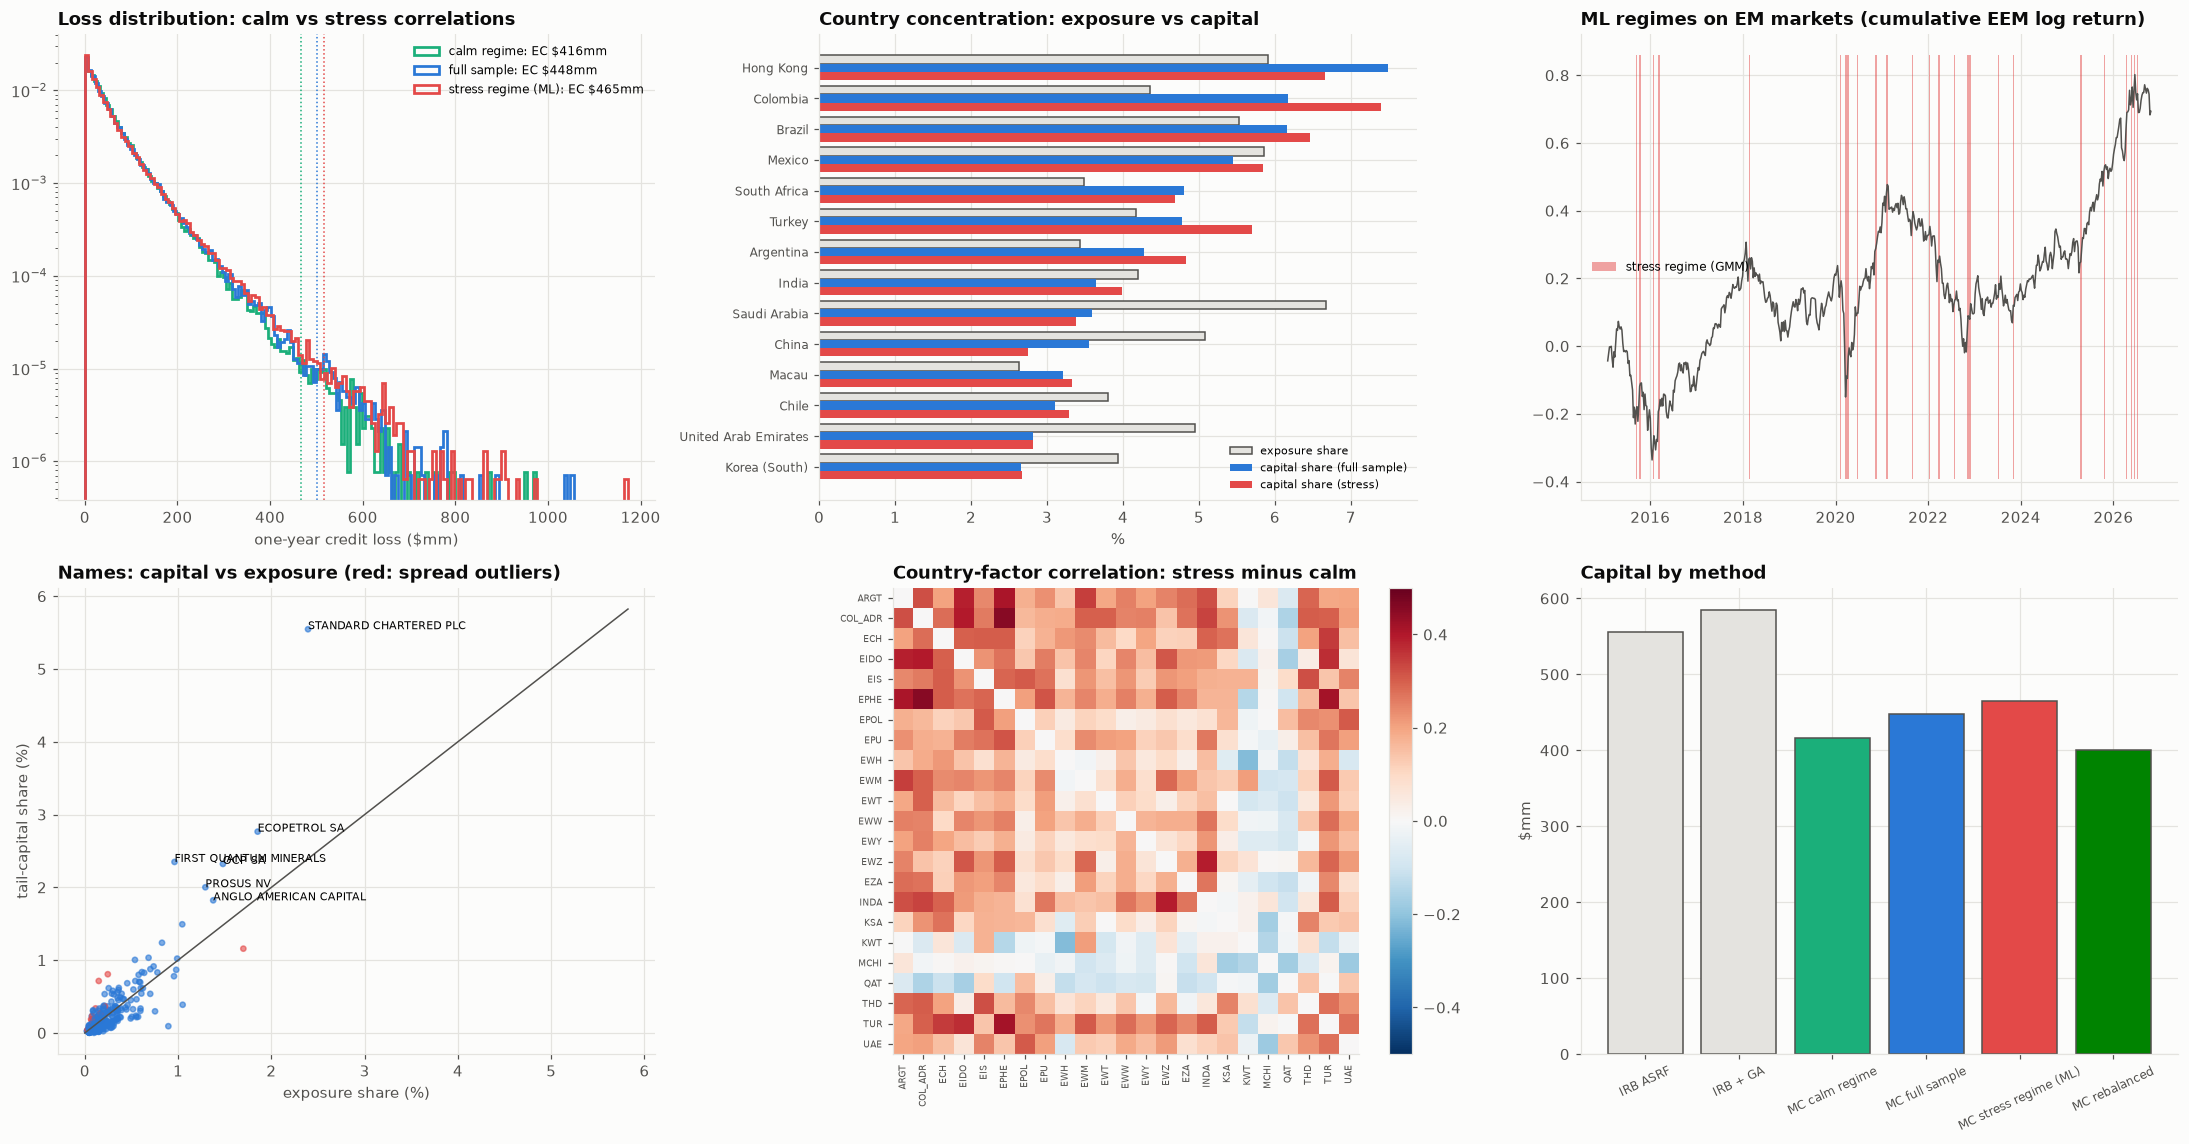

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10.5))
ax = axes[0, 0]
for (k, v), c in zip(res_mc.items(), [PALETTE[2], PALETTE[0], PALETTE[7]]):
    ax.hist(v["L"] / 1e6, bins=150, density=True, histtype="step", lw=1.8, color=c, label=f"{k}: EC ${v['EC'] / 1e6:,.0f}mm")
    ax.axvline(v["VaR"] / 1e6, color=c, ls=":", lw=1)
ax.set_yscale("log"); ax.set_xlabel("one-year credit loss ($mm)"); ax.set_title("Loss distribution: calm vs stress correlations"); ax.legend(fontsize=8)
ax = axes[0, 1]
top = by_cty.sort_values("capital_share", ascending=False).head(14)
yy = np.arange(len(top))
ax.barh(yy - 0.27, top["EAD_share"] * 100, 0.27, color=GRID, edgecolor=INK_2, label="exposure share")
ax.barh(yy, top["capital_share"] * 100, 0.27, color=PALETTE[0], label="capital share (full sample)")
ax.barh(yy + 0.27, top["capital_share_stress"] * 100, 0.27, color=PALETTE[7], label="capital share (stress)")
ax.set_yticks(yy); ax.set_yticklabels(top.index, fontsize=8); ax.invert_yaxis(); ax.set_xlabel("%"); ax.legend(fontsize=7)
ax.set_title("Country concentration: exposure vs capital")
ax = axes[0, 2]
ax.plot(regime.index, ret["EEM"].reindex(regime.index).cumsum(), color=INK_2, lw=1)
ymin, ymax = ax.get_ylim()
ax.fill_between(regime.index, ymin, ymax, where=regime.values, color=PALETTE[7], alpha=0.5, lw=0, step="mid", label="stress regime (GMM)")
ax.set_title("ML regimes on EM markets (cumulative EEM log return)"); ax.legend(fontsize=8)
ax = axes[1, 0]
ax.scatter(iss["EAD_share"] * 100, iss["contrib_share"] * 100, s=12, alpha=0.6, c=np.where(iss["outlier"], PALETTE[7], PALETTE[0]))
lim = max(iss["EAD_share"].max(), iss["contrib_share"].max()) * 100 * 1.05
ax.plot([0, lim], [0, lim], color=INK_2, lw=1); ax.set_xlabel("exposure share (%)"); ax.set_ylabel("tail-capital share (%)")
ax.set_title("Names: capital vs exposure (red: spread outliers)")
for _, rw in iss.nlargest(6, "contrib_share").iterrows():
    ax.annotate(rw["issuer"][:22], (rw["EAD_share"] * 100, rw["contrib_share"] * 100), fontsize=7)
ax = axes[1, 1]
im = ax.imshow(corr_stress.values[np.ix_(cty, cty)] - corr_calm.values[np.ix_(cty, cty)], cmap="RdBu_r", vmin=-0.5, vmax=0.5)
labs = [FACT[i] for i in cty]
ax.set_xticks(range(len(cty))); ax.set_xticklabels(labs, rotation=90, fontsize=6); ax.set_yticks(range(len(cty))); ax.set_yticklabels(labs, fontsize=6)
plt.colorbar(im, ax=ax, fraction=0.046); ax.set_title("Country-factor correlation: stress minus calm"); ax.grid(False)
ax = axes[1, 2]
capv = pd.Series({"IRB ASRF": np.sum(K * EAD) / 1e6, "IRB + GA": (np.sum(K * EAD) + GA * EAD.sum()) / 1e6,
                  **{f"MC {k}": v["EC"] / 1e6 for k, v in res_mc.items()}, "MC rebalanced": reb.loc["economic capital ($mm)", "rebalanced"]})
ax.bar(range(len(capv)), capv.values, color=[GRID, GRID, PALETTE[2], PALETTE[0], PALETTE[7], PALETTE[5]], edgecolor=INK_2)
ax.set_xticks(range(len(capv))); ax.set_xticklabels(capv.index, rotation=25, fontsize=8); ax.set_ylabel("$mm"); ax.set_title("Capital by method")
plt.tight_layout()
save_fig(fig, "01_concentration_capital_regimes")
plt.show()

## 10. Reading the results and limitations

**What the numbers say.**

- **Names look granular; countries and sectors do not.** 574 obligors give an effective number of about 211 names, and the top five hold 9% of the book. The effective number of countries is only about 27, and of sectors under 4. The granularity adjustment adds about **$29mm (5%)** to the $556mm IRB capital, which is small. Name concentration is not the main problem in this book.
- **The single-factor IRB number is conservative here.** The multi-factor Monte Carlo, with country and sector factors estimated from market data, gives economic capital of about **$448mm**, roughly 77% of IRB + GA. The Basel correlations (12–24%) are calibrated to be prudent for any portfolio, and a book spread over 57 countries does diversify. The point of the model is **where** the capital sits.
- **Capital concentrates in a few countries and names.** Several countries consume more capital than their share of exposure:
  - Hong Kong: 7.5% of capital for 5.9% of exposure;
  - Colombia: 6.2% for 4.4% (ratio 1.42, the highest among large countries);
  - South Africa: ratio 1.38;
  - Brazil, Argentina and Turkey.
  
  China, Saudi Arabia, the UAE and India consume less than their share. Colombia's ratio comes from a few large, high-spread names (Ecopetrol alone takes 2.8% of tail capital) and a volatile country factor. Standard Chartered, the largest single obligor, takes 5.5% of tail capital.
- **ML regimes: diversification shrinks in stress.** The Gaussian mixture flags 17% of weeks as stress, including most of March 2020 and April 2025. The average correlation between country factors rises from 0.38 in calm weeks to 0.51 in stress weeks. Run through the same book, economic capital goes from **$416mm (calm) to $465mm (stress), +12%**. A limit framework calibrated on calm-period correlations understates concentration exactly when it matters.
- **Spread outliers matter more than their size.** The LightGBM "fundamentals spread" (country-grouped CV R² 0.52) flags 18 names whose market spread is more than three times the model's. They are 3.4% of exposure but 5.1% of tail capital. Whether they are true credit stories or event or liquidity noise is a credit-analyst question; the model's job is to put them on the list.
- **Rebalancing cuts capital, not income.** With each name allowed to move ±30% and capital priced at its Euler gradient, the optimiser keeps net spread income unchanged ($124mm) and lowers simulated economic capital from $448mm to **$401mm (−11%)**. Return on capital rises from 27.8% to 31.1%. Name HHI falls, but country HHI rises slightly: the optimiser moves exposure towards countries with low correlation to the rest, so a country-limit constraint would be the natural next addition.

**Limitations.**
- PDs come from spreads with an assumed risk-neutral/physical ratio of 2.5; the ranking is robust but the level of capital scales with that assumption.
- Equity ETFs proxy credit factors. Colombia is proxied by two ADRs, and countries without an ETF fall back to EEM.
- The horizon is one year, with no migration risk, no maturity adjustment and LGDs independent of the factors. A wrong-way LGD would raise stress capital further.
- The stress regime has about 100 weeks, so its correlation matrix is noisier; the rebalancing uses first-order Euler gradients, which is why it is re-checked by full simulation.

In [10]:
conc.to_csv(OUT_DIR / "concentration_indices.csv")
cap.to_csv(OUT_DIR / "irb_and_granularity.csv", header=["value"])
mc_tab.to_csv(OUT_DIR / "monte_carlo_capital_by_regime.csv")
by_cty.to_csv(OUT_DIR / "country_capital_contributions.csv")
by_sec.to_csv(OUT_DIR / "sector_capital_contributions.csv")
reb.to_csv(OUT_DIR / "rebalancing.csv")
iss[["issuer", "country", "sector", "EAD", "s5", "s5_model", "PD", "contrib_share", "outlier", "EAD_new"]].to_csv(OUT_DIR / "obligor_detail.csv", index=False)
print("Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir())))

Outputs written: 01_concentration_capital_regimes.png, concentration_indices.csv, country_capital_contributions.csv, irb_and_granularity.csv, monte_carlo_capital_by_regime.csv, obligor_detail.csv, rebalancing.csv, sector_capital_contributions.csv
